In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew, kurtosis, pearsonr, spearmanr
SCRIPT_DIR = Path.cwd()
DATA_PATH = SCRIPT_DIR / "USSeatBelts.csv"
if not DATA_PATH.exists():
    DATA_PATH = SCRIPT_DIR.parent / "USSeatBelts.csv"
if not DATA_PATH.exists() and (SCRIPT_DIR / "USSeatBelts.csv").exists():
    DATA_PATH = SCRIPT_DIR / "USSeatBelts.csv"
def load_seatbelts():
    if not DATA_PATH.exists():
        raise FileNotFoundError(
            f"Could not find the dataset at {DATA_PATH}.\n"
            "Place USSeatBelts.csv"
            "in the same folder as this script."
        )
    return pd.read_csv(DATA_PATH)

In [2]:
def show_data(df):
    print("\nDATASET INFORMATION")
    print("\nShape:", df.shape)
    print("\nColumns:", list(df.columns))
    print("\nData types:")
    df.info()

    print("\nFirst six rows:")
    print(df.head(6).to_string())

    print("\nLast six rows:")
    print(df.tail(6).to_string())

    print("\nSummary statistics:")
    print(df.describe(include="all").T.to_string())
df = load_seatbelts()
show_data(df)
required_columns = [
    "fatalities", "seatbelt", "speed65", "speed70",
    "miles", "income", "age"
]
missing_columns = [col for col in required_columns if col not in df.columns]
if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")


DATASET INFORMATION

Shape: (765, 13)

Columns: ['rownames', 'state', 'year', 'miles', 'fatalities', 'seatbelt', 'speed65', 'speed70', 'drinkage', 'alcohol', 'income', 'age', 'enforce']

Data types:
<class 'pandas.DataFrame'>
RangeIndex: 765 entries, 0 to 764
Data columns (total 13 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   rownames    765 non-null    int64  
 1   state       765 non-null    str    
 2   year        765 non-null    int64  
 3   miles       765 non-null    int64  
 4   fatalities  765 non-null    float64
 5   seatbelt    556 non-null    float64
 6   speed65     765 non-null    str    
 7   speed70     765 non-null    str    
 8   drinkage    765 non-null    str    
 9   alcohol     765 non-null    str    
 10  income      765 non-null    int64  
 11  age         765 non-null    float64
 12  enforce     765 non-null    str    
dtypes: float64(3), int64(4), str(6)
memory usage: 77.8 KB

First six rows:
   rownames sta

In [3]:
# 1-3. DESCRIPTIVE STATISTICS

x = pd.to_numeric(df["fatalities"], errors="coerce").dropna()

stats = {
    "Mean": x.mean(),
    "Median": x.median(),
    "Minimum": x.min(),
    "Maximum": x.max(),
    "Range": x.max() - x.min(),
    "Variance": x.var(),
    "Standard Deviation": x.std(),
    "IQR": x.quantile(0.75) - x.quantile(0.25),
    "Skewness": skew(x),
    "Kurtosis": kurtosis(x)
}

print("\nFATALITIES SUMMARY STATISTICS")
print(pd.Series(stats).to_string())


FATALITIES SUMMARY STATISTICS
Mean                  0.021490
Median                0.021199
Minimum               0.008327
Maximum               0.045470
Range                 0.037143
Variance              0.000038
Standard Deviation    0.006171
IQR                   0.007433
Skewness              0.758534
Kurtosis              0.798229



SEATBELT FREQUENCY DISTRIBUTION
seatbelt
NaN       209
0.5800     15
0.6400     14
0.5500     13
0.5400     13
0.6300     13
0.5900     13
0.5000     11
0.7100     11
0.6200     11
0.7000     11
0.5600     10
0.3200     10
0.6900      9
0.5300      9
0.6100      9
0.2600      8
0.5200      7
0.7200      7
0.3300      7
0.4300      7
0.6700      7
0.3600      7
0.6600      6
0.4800      6
0.6500      6
0.4900      6
0.8000      6
0.7500      6
0.4500      5
0.2900      5
0.4700      5
0.5100      5
0.6000      5
0.6800      5
0.4200      5
0.3400      4
0.7300      4
0.3500      4
0.4000      4
0.3000      4
0.1300      3
0.3800      3
0.1800      3
0.3900      3
0.4100      3
0.8500      3
0.7400      3
0.6750      3
0.2100      2
0.4400      2
0.1980      2
0.4710      2
0.6270      2
0.4610      2
0.4600      2
0.5040      2
0.6420      2
0.4410      2
0.2000      2
0.5700      2
0.6720      2
0.7900      2
0.2800      2
0.1500      2
0.2630      2
0.7010      2
0.5150      2
0.4660

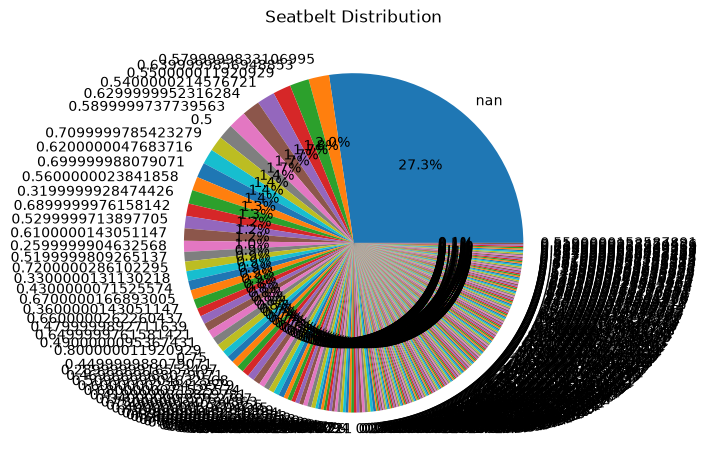

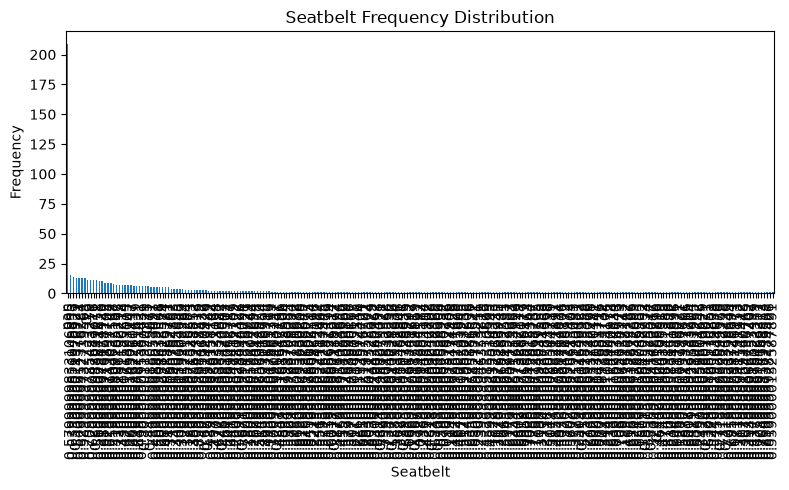

In [4]:
# 4. FREQUENCY AND RELATIVE FREQUENCY DISTRIBUTIONS

freq = df["seatbelt"].value_counts(dropna=False)
relative_freq = freq / freq.sum()

print("\nSEATBELT FREQUENCY DISTRIBUTION")
print(freq.to_string())

print("\nSEATBELT RELATIVE FREQUENCY DISTRIBUTION")
print(relative_freq.to_string())

print("\nSEATBELT PERCENTAGE DISTRIBUTION")
print((relative_freq * 100).round(2).to_string())

freq.plot(
    kind="pie",
    autopct="%1.1f%%",
    figsize=(7, 7),
    title="Seatbelt Distribution"
)
plt.ylabel("")
plt.tight_layout()
plt.show()

freq.plot(
    kind="bar",
    figsize=(8, 5),
    title="Seatbelt Frequency Distribution"
)
plt.xlabel("Seatbelt")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


FATALITIES FREQUENCY DISTRIBUTION BY INTERVAL
fatalities
(0.00829, 0.012]     25
(0.012, 0.0158]     104
(0.0158, 0.0195]    190
(0.0195, 0.0232]    195
(0.0232, 0.0269]    121
(0.0269, 0.0306]     59
(0.0306, 0.0343]     45
(0.0343, 0.038]      16
(0.038, 0.0418]       6
(0.0418, 0.0455]      4


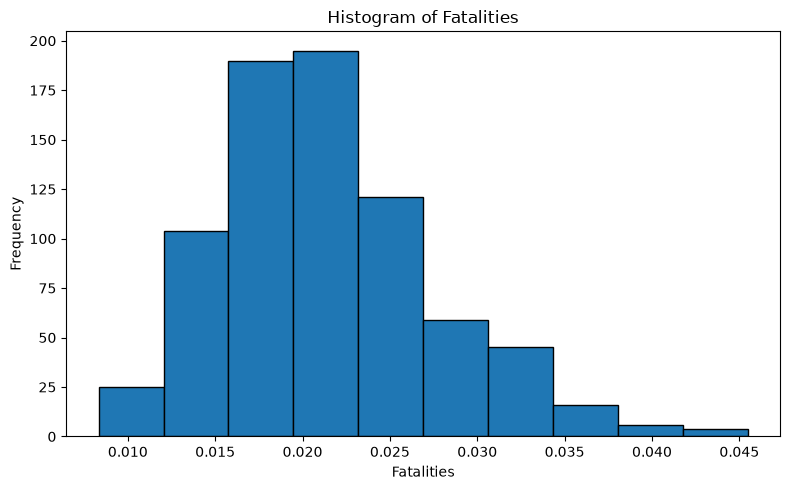

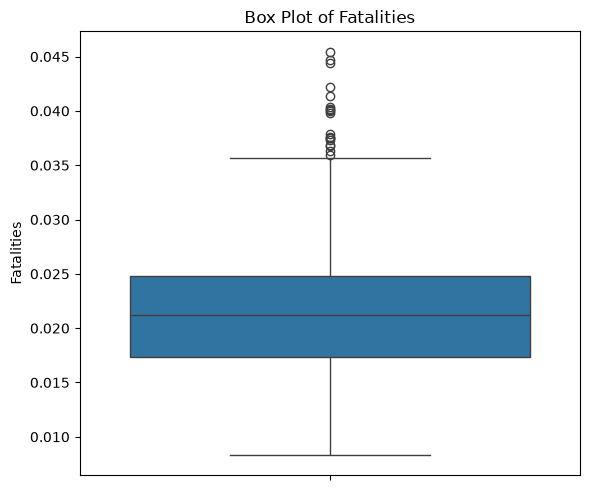

In [5]:
# 5. NUMERICAL FREQUENCY TABLE, HISTOGRAM AND BOX PLOT

bins = pd.cut(x, bins=10)

print("\nFATALITIES FREQUENCY DISTRIBUTION BY INTERVAL")
print(bins.value_counts().sort_index().to_string())

plt.figure(figsize=(8, 5))
plt.hist(x, bins=10, edgecolor="black")
plt.title("Histogram of Fatalities")
plt.xlabel("Fatalities")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 5))
sns.boxplot(y=x)
plt.title("Box Plot of Fatalities")
plt.ylabel("Fatalities")
plt.tight_layout()
plt.show()


CONTINGENCY TABLE: SPEED65 VS SPEED70
speed70   no  yes
speed65          
no       271    0
yes      440   54

ROW PROPORTIONS
speed70      no     yes
speed65                
no       1.0000  0.0000
yes      0.8907  0.1093

COLUMN PROPORTIONS
speed70      no  yes
speed65             
no       0.3812  0.0
yes      0.6188  1.0


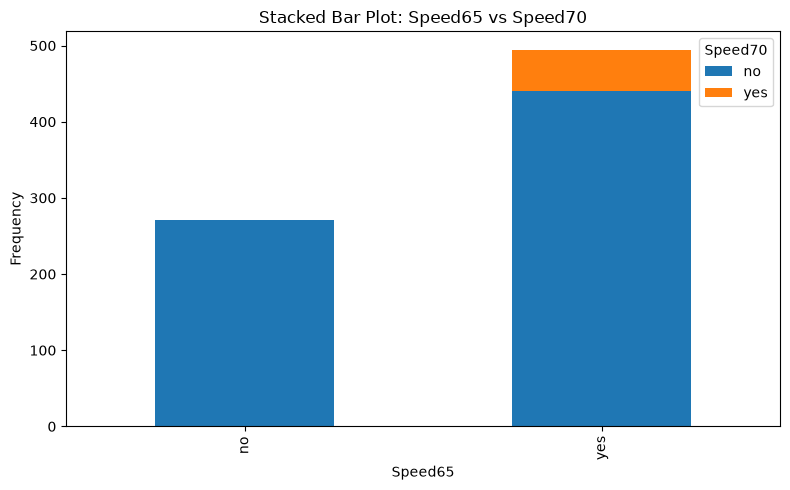

In [6]:
# 6-7. CONTINGENCY TABLE, PROPORTIONS AND STACKED BAR PLOT

ct = pd.crosstab(df["speed65"], df["speed70"])

print("\nCONTINGENCY TABLE: SPEED65 VS SPEED70")
print(ct.to_string())

print("\nROW PROPORTIONS")
print(pd.crosstab(
    df["speed65"], df["speed70"], normalize="index"
).round(4).to_string())

print("\nCOLUMN PROPORTIONS")
print(pd.crosstab(
    df["speed65"], df["speed70"], normalize="columns"
).round(4).to_string())

ct.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5),
    title="Stacked Bar Plot: Speed65 vs Speed70"
)
plt.xlabel("Speed65")
plt.ylabel("Frequency")
plt.legend(title="Speed70")
plt.tight_layout()
plt.show()

In [7]:
# 8. GROUPED MEAN, MEDIAN AND STANDARD DEVIATION

df["fatalities"] = pd.to_numeric(df["fatalities"], errors="coerce")

grouped_stats = df.groupby(
    "speed65", observed=False
)["fatalities"].agg(["mean", "median", "std"])

print("\nFATALITIES STATISTICS GROUPED BY SPEED65")
print(grouped_stats.to_string())


FATALITIES STATISTICS GROUPED BY SPEED65
             mean    median       std
speed65                              
no       0.023836  0.022840  0.007072
yes      0.020202  0.019554  0.005191


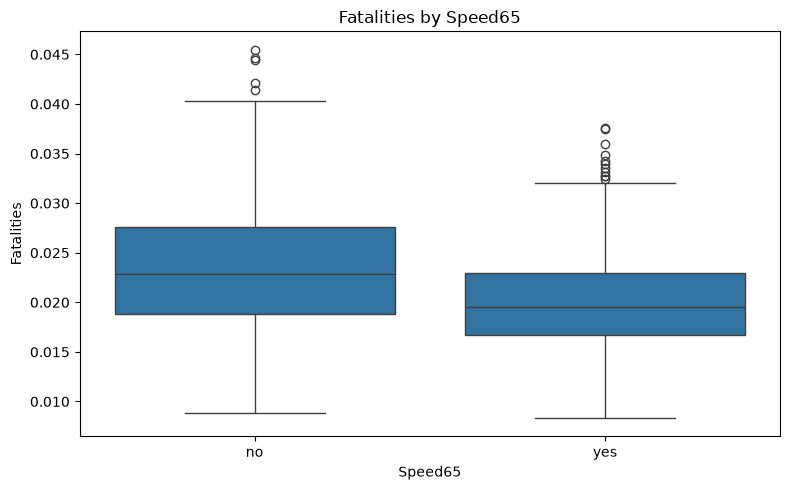

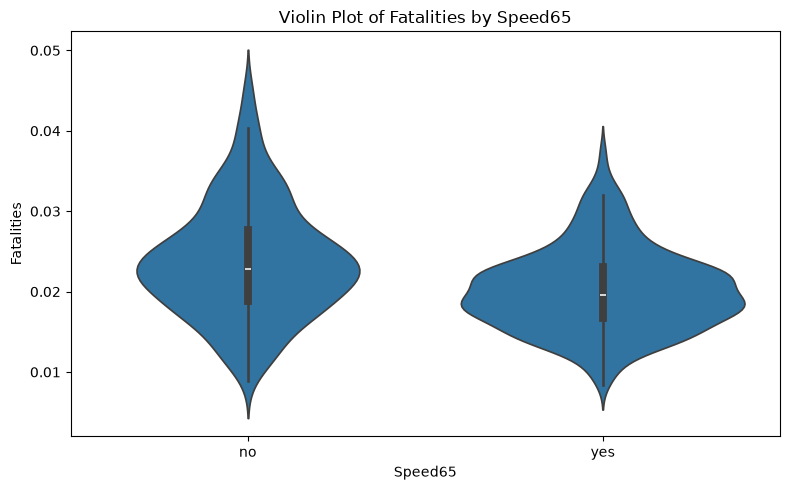

In [8]:
# 9. SIDE-BY-SIDE BOX PLOT AND VIOLIN PLOT

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="speed65", y="fatalities")
plt.title("Fatalities by Speed65")
plt.xlabel("Speed65")
plt.ylabel("Fatalities")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
sns.violinplot(data=df, x="speed65", y="fatalities")
plt.title("Violin Plot of Fatalities by Speed65")
plt.xlabel("Speed65")
plt.ylabel("Fatalities")
plt.tight_layout()
plt.show()


PEARSON CORRELATION
PearsonRResult(statistic=np.float64(-0.16136607147560542), pvalue=np.float64(7.281379796112726e-06))

SPEARMAN CORRELATION
SignificanceResult(statistic=np.float64(-0.1512044260875675), pvalue=np.float64(2.6758003710262204e-05))


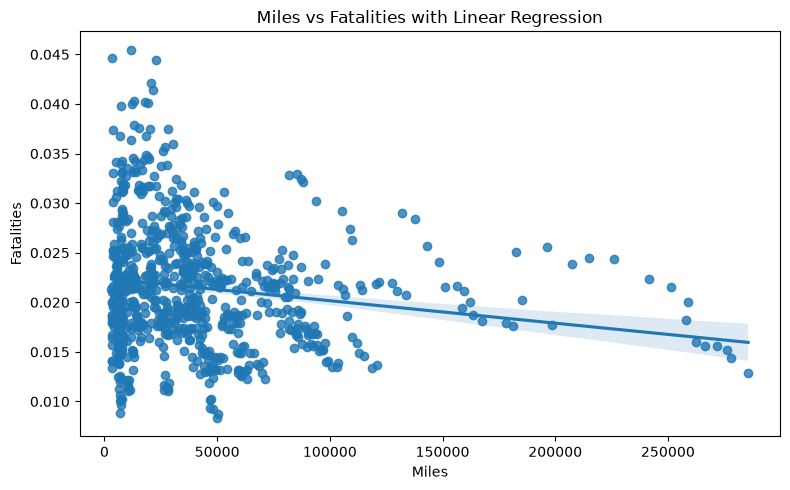

In [9]:
# 10. PEARSON AND SPEARMAN CORRELATIONS

paired = df[["miles", "fatalities"]].apply(
    pd.to_numeric, errors="coerce"
).dropna()

if len(paired) >= 2:
    print("\nPEARSON CORRELATION")
    print(pearsonr(paired["miles"], paired["fatalities"]))

    print("\nSPEARMAN CORRELATION")
    print(spearmanr(paired["miles"], paired["fatalities"]))

plt.figure(figsize=(8, 5))
sns.regplot(data=paired, x="miles", y="fatalities")
plt.title("Miles vs Fatalities with Linear Regression")
plt.xlabel("Miles")
plt.ylabel("Fatalities")
plt.tight_layout()
plt.show()


MEAN AND STANDARD DEVIATION BY SPEED65 AND SPEED70
speed65 speed70     mean      std  count
     no      no 0.023836 0.007072    271
    yes      no 0.020254 0.005359    440
    yes     yes 0.019778 0.003545     54


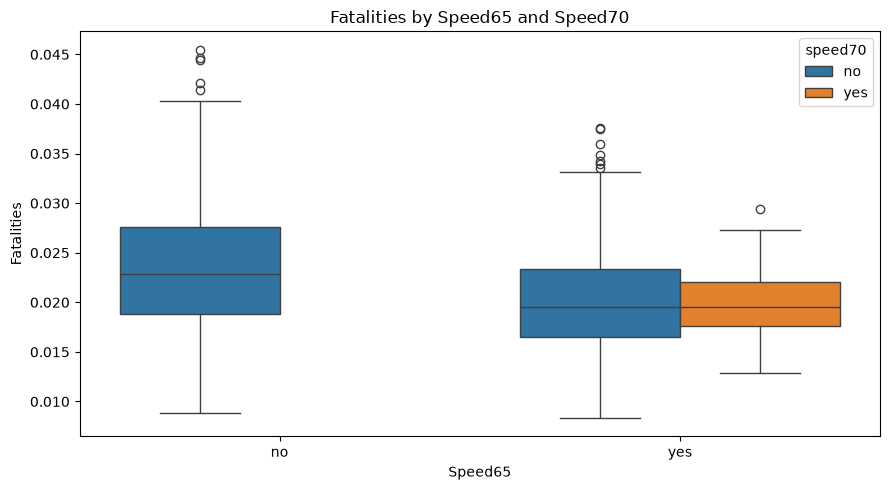

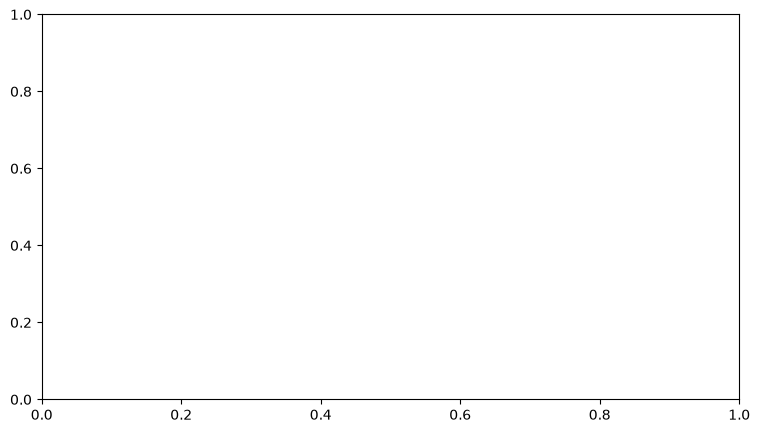

In [10]:
# 11. TWO CATEGORICAL VARIABLES AND ONE NUMERICAL VARIABLE
grouped = df.groupby(
    ["speed65", "speed70"], observed=False
)["fatalities"].agg(["mean", "std", "count"]).reset_index()
print("\nMEAN AND STANDARD DEVIATION BY SPEED65 AND SPEED70")
print(grouped.to_string(index=False))
plt.figure(figsize=(9, 5))
sns.boxplot(
    data=df,
    x="speed65",
    y="fatalities",
    hue="speed70"
)
plt.title("Fatalities by Speed65 and Speed70")
plt.xlabel("Speed65")
plt.ylabel("Fatalities")
plt.tight_layout()
plt.show()
# Grouped mean bar chart with standard-deviation error bars
categories65 = list(df["speed65"].dropna().unique())
categories70 = list(df["speed70"].dropna().unique())
positions = np.arange(len(categories65))
width = 0.8 / max(len(categories70), 1)
fig, ax = plt.subplots(figsize=(9, 5))

In [11]:
for j, category70 in enumerate(categories70):
    subset = (
        grouped[grouped["speed70"] == category70]
        .set_index("speed65")
        .reindex(categories65)
    )

    offsets = positions - 0.4 + width / 2 + j * width

    ax.bar(
        offsets,
        subset["mean"],
        width=width,
        yerr=subset["std"],
        capsize=4,
        label=f"Speed70 = {category70}"
    )
ax.set_xticks(positions)
ax.set_xticklabels([str(category) for category in categories65])
ax.set_xlabel("Speed65")
ax.set_ylabel("Mean Fatalities")
ax.set_title("Mean Fatalities by Speed Categories with SD Error Bars")
ax.legend()
plt.tight_layout()
plt.show()

<Figure size 640x480 with 0 Axes>

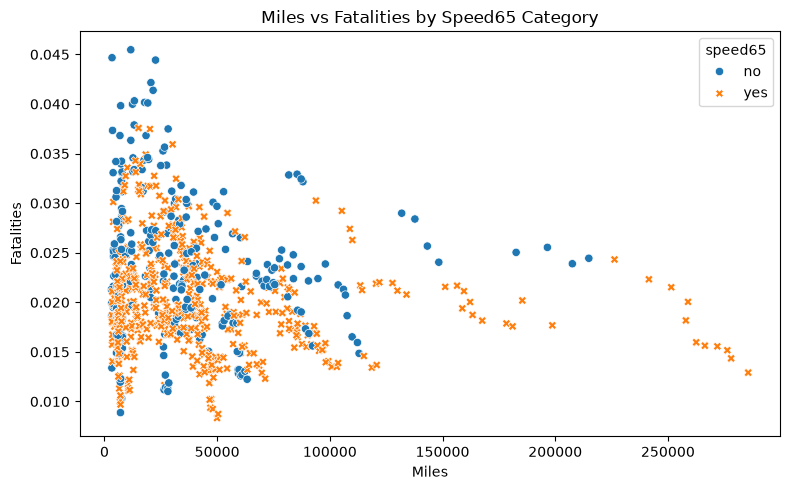


CORRELATIONS BY SPEED65 CATEGORY

Speed65 = no
Pearson correlation: -0.12218402764840869
Spearman correlation: -0.12094913565985152

Speed65 = yes
Pearson correlation: -0.1660640208506913
Spearman correlation: -0.15867439599552358


In [12]:
# 12. CATEGORY-COLORED SCATTER PLOT AND CATEGORY-WISE CORRELATIONS

plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x="miles",
    y="fatalities",
    hue="speed65",
    style="speed65"
)
plt.title("Miles vs Fatalities by Speed65 Category")
plt.xlabel("Miles")
plt.ylabel("Fatalities")
plt.tight_layout()
plt.show()

print("\nCORRELATIONS BY SPEED65 CATEGORY")

for category, group in df.groupby("speed65", observed=False):
    subset = group[["miles", "fatalities"]].apply(
        pd.to_numeric, errors="coerce"
    ).dropna()

    print(f"\nSpeed65 = {category}")

    if len(subset) >= 2 and subset["miles"].nunique() > 1 and subset["fatalities"].nunique() > 1:
        print(
            "Pearson correlation:",
            subset["miles"].corr(
                subset["fatalities"], method="pearson"
            )
        )
        print(
            "Spearman correlation:",
            subset["miles"].corr(
                subset["fatalities"], method="spearman"
            )
        )
    else:
        print("Insufficient variation or observations for correlation.")


CORRELATION MATRIX
             miles  fatalities  income     age
miles       1.0000     -0.1614  0.2062  0.0835
fatalities -0.1614      1.0000 -0.7036 -0.3754
income      0.2062     -0.7036  1.0000  0.4075
age         0.0835     -0.3754  0.4075  1.0000


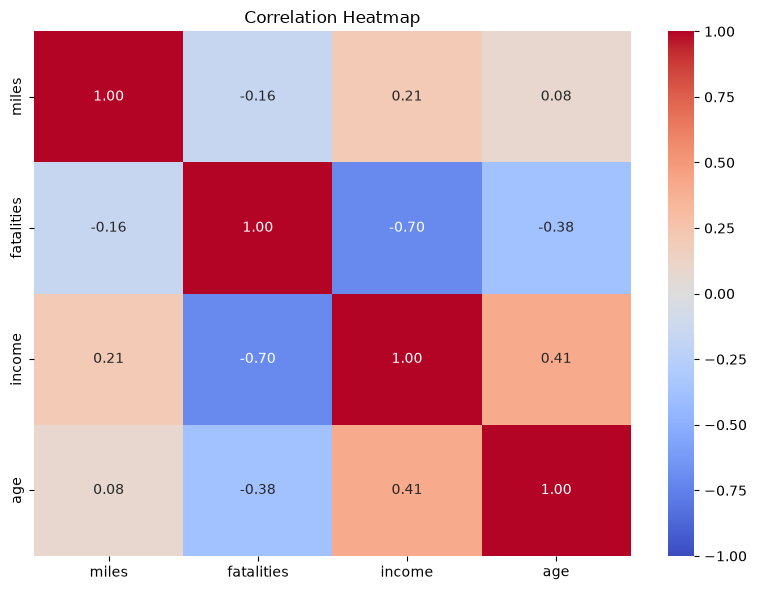

In [13]:
# 13. CORRELATION MATRIX AND HEATMAP

num = df[["miles", "fatalities", "income", "age"]].apply(
    pd.to_numeric, errors="coerce"
)

corr_matrix = num.corr()

print("\nCORRELATION MATRIX")
print(corr_matrix.round(4).to_string())

plt.figure(figsize=(8, 6))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".2f"
)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

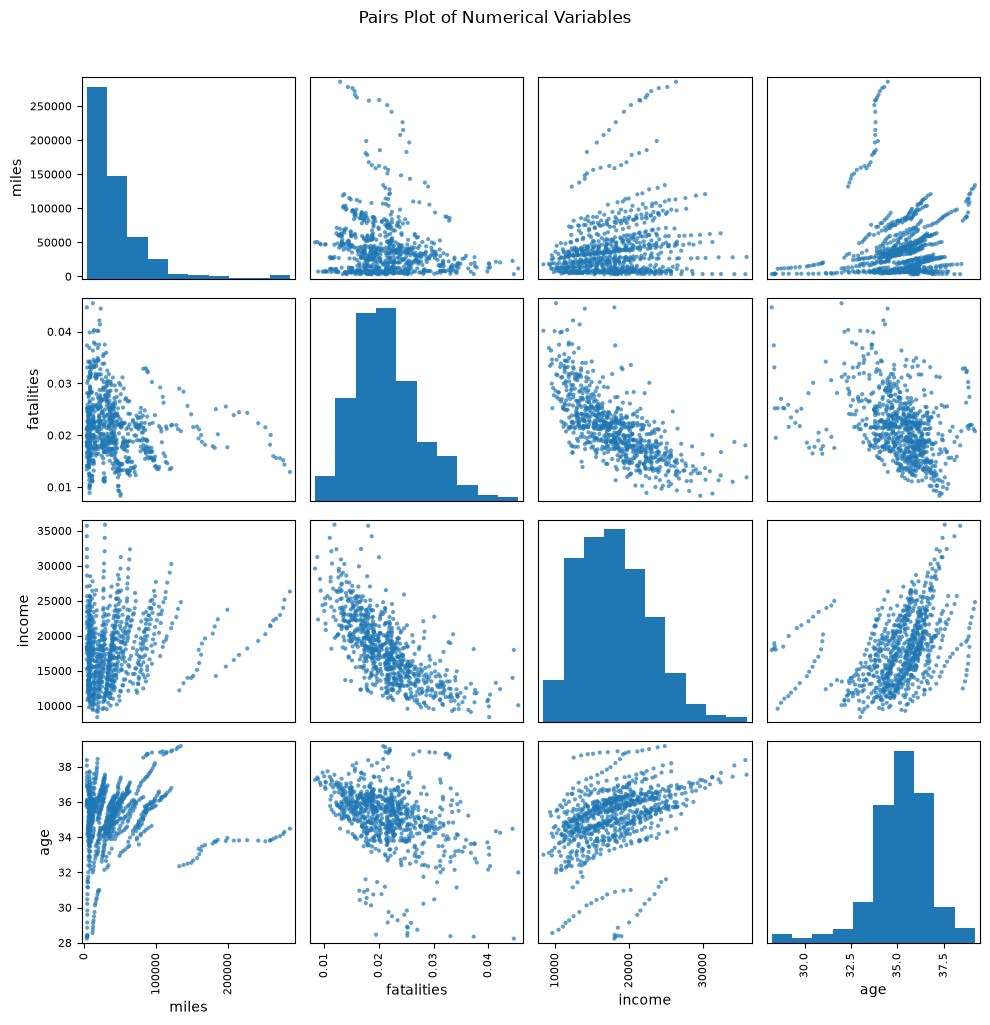

In [14]:
# 14. PAIRS PLOT / SCATTERPLOT MATRIX

pairs_data = num.dropna()

pd.plotting.scatter_matrix(
    pairs_data,
    figsize=(10, 10),
    diagonal="hist",
    alpha=0.7
)

plt.suptitle("Pairs Plot of Numerical Variables", y=1.02)
plt.tight_layout()
plt.show()